# Project Galicia · Business plan estocástico de Inditex (2026–2030)

**Objetivo.** Proyectar la caja que Inditex puede generar para servir la deuda del LBO y medir, con datos, cuánto se puede apalancar y qué rentabilidad cabe esperar.

**Operación analizada** (decisión del grupo): OPA por el 100 %, prima del 20 %, el 50 % de la participación de Amancio Ortega reinvierte en la TopCo (*rollover*) y deuda de ≈ 7,0x EBITDA pre-IFRS 16 (TLA 2,25x + TLB 2,25x + HoldCo PIK 1,5x + vendor loan 1,0x).

**Qué aporta este enfoque frente a tres escenarios a mano:**

1. Cada hipótesis sale de **20 años de histórico** (2005–2025) y está calibrada estadísticamente.
2. En lugar de 3 escenarios, **20.000 futuros simulados** con incertidumbre de proceso (shocks anuales) y paramétrica (no conocemos con exactitud ni las medias de largo plazo).
3. Los casos Bull/Base/Bear/Bank que pide el Excel **salen de percentiles de la simulación**, no de la intuición.
4. La deuda se dimensiona con una **restricción probabilística** (P(incumplir covenant) ≤ 5 %), y se cuantifica qué parte del riesgo de la TIR explica cada driver (**valores de Shapley**).

Todo el cálculo está en el paquete `bp/` y el motor LBO replica **fórmula a fórmula** la hoja `LBO_Rollover50` del Excel del grupo (los tests lo comprueban contra los valores de Excel).

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.max_colwidth", 120)

from bp import analysis as A
from bp.pipeline import build, case_summary, MARKET_MULTIPLE
from bp.lbo import run, JAVI_DEAL, GROUP_DEAL, excel_base_operating, sources_and_uses

o = build()          # calibración → 20.000 caminos → casos → LBO → riesgo → gráficos (≈ 10 s)
fig = lambda name: display(Image(filename=str(ROOT / "figures" / name), width=900))
es = lambda v, f: format(v, f).replace(",", "§").replace(".", ",").replace("§", ".")  # formato español

findfont: Failed to find font weight semibold for Helvetica Neue, now using 700.


In [2]:
res, ex = o["res"], o["excel_res"]
display(Markdown(f'''
### Resumen ejecutivo

| | Excel del grupo (caso base) | Business plan simulado (mediana) |
|---|---|---|
| EBITDA pre-IFRS 16 2030 | {es(o["excel_op"].ebitda_pre[0,-1], ",.0f")} M€ | {es(np.median(o["op"].ebitda_pre[:,-1]), ",.0f")} M€ (P5–P95: {es(np.percentile(o["op"].ebitda_pre[:,-1],5), ",.0f")}–{es(np.percentile(o["op"].ebitda_pre[:,-1],95), ",.0f")}) |
| Percentil del EBITDA del Excel en la simulación | — | **{o["excel_pctile"]:.0f}** |
| TIR del sponsor | {es(ex["irr"][0], ".1%")} | **{es(np.median(res["irr"]), ".1%")}** (P10 {es(np.percentile(res["irr"],10), ".1%")} · P90 {es(np.percentile(res["irr"],90), ".1%")}) |
| P(TIR ≥ 15 %) | — | {es((res["irr"]>=0.15).mean(), ".1%")} |
| P(DSCR mínimo < 1,2x) | {"0 %" if ex["min_dscr"][0]>=1.2 else "100 %"} | {es((res["min_dscr"]<1.2).mean(), ".0%")} |
'''))


### Resumen ejecutivo

| | Excel del grupo (caso base) | Business plan simulado (mediana) |
|---|---|---|
| EBITDA pre-IFRS 16 2030 | 13.577 M€ | 11.011 M€ (P5–P95: 8.073–13.575) |
| Percentil del EBITDA del Excel en la simulación | — | **95** |
| TIR del sponsor | 11,3% | **4,9%** (P10 -1,5% · P90 10,0%) |
| P(TIR ≥ 15 %) | — | 0,4% |
| P(DSCR mínimo < 1,2x) | 0 % | 71% |


## 1. Qué es el business plan en un LBO

En un LBO la deuda no la paga el fondo: la paga **la caja que genera la empresa**. El business plan es la proyección de esa caja:

$$\text{CFADS}_t = \text{EBITDA pre-IFRS 16}_t - \text{Impuestos}_t - \text{Capex}_t - \Delta \text{Circulante}_t$$

Con ella el compañero de deuda calcula el **DSCR** (CFADS / intereses + amortización) y el resto del grupo la TIR. Por eso el business plan decide cuánta deuda cabe: más caja → más deuda soportable.

Usamos el **EBITDA pre-IFRS 16** (restando los alquileres fijos de tiendas, 1.834 M€ en 2025), porque los alquileres son un pago real de caja que la norma IFRS 16 saca del EBITDA reportado.

## 2. Datos

* `data/inditex_history_2005_2025.csv`: ventas, crecimiento reportado y a tipo de cambio constante, margen bruto y EBITDA. 2021–2025 de las cuentas anuales del repositorio; 2005–2020 de resultados publicados y prensa financiera (fuente por fila; el EBITDA 2018 está marcado como no verificado).
* `data/inditex_operating_detail_2021_2025.csv`: superficie de venta (m²) por marca, ventas por geografía, ventas online y desglose de gastos, de las cuentas anuales.

Hasta 2018 el EBITDA se publicaba con la norma antigua (IAS 17), que ya restaba los alquileres; desde 2021 lo reconstruimos como EBITDA reportado − pagos fijos de arrendamiento. Así tenemos **una serie homogénea de EBITDA pre-IFRS 16**, que es justo la variable que dimensiona la deuda.

In [3]:
h = o["cal"].history
cols = ["net_sales_eur_m", "growth", "growth_constant_fx_pct", "gm", "opex_ratio", "ebitda_margin_pre", "status"]
h[cols].rename(columns={"net_sales_eur_m": "ventas €m", "growth": "crec. reportado", "growth_constant_fx_pct": "crec. tc constante (%)",
                        "gm": "margen bruto", "opex_ratio": "gastos/ventas pre-IFRS16", "ebitda_margin_pre": "margen EBITDA pre-IFRS16",
                        "status": "fuente"})

,ventas €m,crec. reportado,crec. tc constante (%),margen bruto,gastos/ventas pre-IFRS16,margen EBITDA pre-IFRS16,fuente
fiscal_year,,,,,,,
2005,6741,NaN,NaN,0.562,NaN,NaN,prensa
2006,8196,0.216,NaN,NaN,NaN,NaN,prensa
2007,9435,0.151,NaN,NaN,NaN,NaN,derivado
2008,10407,0.103,NaN,NaN,NaN,0.210,prensa
2009,11084,0.065,9.000,0.571,0.357,0.214,prensa
2010,12527,0.130,NaN,0.593,0.356,0.237,derivado
2011,13793,0.101,11.000,0.593,0.357,0.236,prensa
2012,15946,0.156,14.000,0.598,0.353,0.245,oficial
2013,16724,0.049,8.000,0.593,0.358,0.235,prensa


## 3. El árbol de crecimiento

Las ventas reportadas en euros se descomponen en tres palancas:

$$1+g^{\text{rep}}_t = \underbrace{(1+g^{\text{m}^2}_t)}_{\text{superficie}}\;\underbrace{(1+g^{\text{dens}}_t)}_{\text{ventas por m}^2\text{ a tc constante}}\;\underbrace{(1+f_t)}_{\text{divisa}}$$

Inditex lleva años cerrando tiendas pequeñas y abriendo grandes (*Retail Optimisation*): la superficie neta crece ≈ 1,8 % al año aunque el número de tiendas baja. La productividad por m² incluye el online (27 % de las ventas en 2025).

In [4]:
d = A_detail = __import__("bp.calibration", fromlist=["load_detail"]).load_detail()
area = d[(d.dimension == "area_m2") & (d.item == "Total")].set_index("fiscal_year").value
geo = d[d.dimension == "sales_geo"].pivot(index="fiscal_year", columns="item", values="value")
online = d[d.dimension == "online_sales"].set_index("fiscal_year").value
tree = pd.DataFrame({
    "Superficie (m²)": area.pct_change(),
    "Productividad/m² (tc constante)": (1 + h.growth_constant_fx_pct / 100) / (1 + area.pct_change()) - 1,
    "Efecto divisa": h.fx_drag,
    "Crecimiento reportado": h.growth,
}).loc[2023:2025]
tree["Ventas online / total"] = (online / h.net_sales_eur_m).loc[2023:2025]
tree["Ventas fuera de Europa"] = ((geo["América"] + geo["Asia y resto del mundo"]) / geo.sum(axis=1)).loc[2023:2025]
tree.T

fiscal_year,2023,2024,2025
Superficie (m²),0.019,0.020,0.015
Productividad/m² (tc constante),0.120,0.083,0.054
Efecto divisa,-0.032,-0.027,-0.036
Crecimiento reportado,0.104,0.075,0.032
Ventas online / total,0.252,0.263,0.267
Ventas fuera de Europa,0.331,0.304,0.291


**Lectura:** la productividad se está normalizando (12 % → 5 %) a medida que desaparece la inflación post-COVID, y **la divisa resta 3–4 puntos al año**: casi un tercio de las ventas son fuera de Europa (América, Asia), en monedas que se deprecian frente al euro.

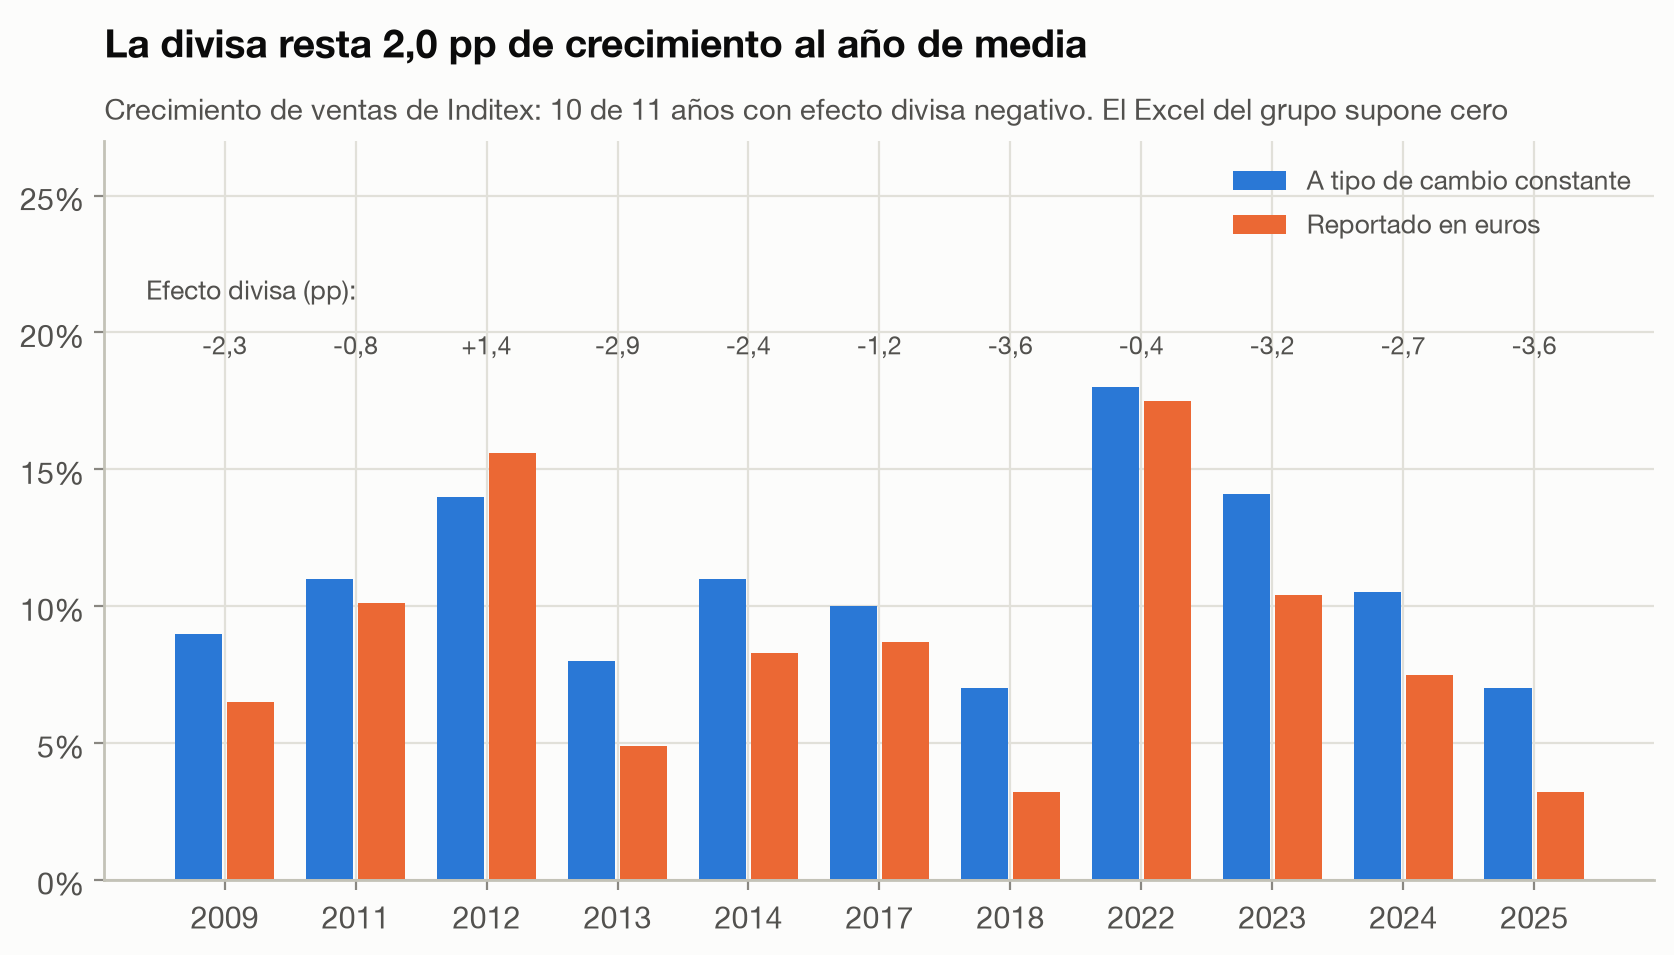

In [5]:
fig("fig2_efecto_divisa.png")

## 4. Calibración: cada hipótesis sale de los datos

### 4.1 Gastos operativos: modelo de corrección de error

El hallazgo más importante del histórico: **los gastos operativos pre-IFRS 16 (incluidos alquileres) se han movido entre el 34,6 % y el 35,8 % de las ventas en todos los años con dato desde 2009** (la única excepción es 2021, aún con restricciones COVID). A largo plazo, los gastos crecen con las ventas.

A corto plazo no: si las ventas sorprenden a la baja, los costes tardan en ajustarse (**apalancamiento operativo**). Lo capturamos con un **modelo de corrección de error (MCE)**, típico en econometría para series cointegradas:

$$\Delta \ln r_t = -(1-\beta)\,\big(\Delta \ln S_t - \bar g_t\big) + \gamma\,\big(\ln r_{t-1} - \ln \bar r\big) + \varepsilon_t$$

donde $r_t$ es el ratio gastos/ventas, $\Delta \ln S_t - \bar g_t$ la sorpresa de ventas frente a su tendencia, $\beta$ la elasticidad a corto plazo de los gastos y $\gamma$ la velocidad a la que el ratio vuelve a su media.

In [6]:
reg = o["cal"].opex_regression
p = o["cal"].params
t_beta, t_gamma = reg["coef"] / reg["se"]
dr, op = o["dr"], o["op"]
m = dr.crisis[:, 0] == 1                      # caminos con crisis en 2026
d_sales = np.median(op.revenue[m, 0] / 39864 - 1)
d_ebitda = np.median(op.ebitda_pre[m, 0] / 9433 - 1)
d_margin = np.median(op.ebitda_pre[m, 0] / op.revenue[m, 0] - 9433 / 39864) * 100
d_wc = np.median(op.wc_cash_flow[m, 0])
display(Markdown(f'''
* **β = {es(p["opex_beta"].value, ".2f")}** (t = {es(abs(t_beta), ".1f")}): ante una sorpresa de ventas de −10 %, los gastos solo bajan un {es(p["opex_beta"].value*10, ".1f")} % → el margen se comprime.
* **γ = {es(p["opex_gamma"].value, ".2f")}** (t = {es(abs(t_gamma), ".1f")}): cada año se corrige el {es(-p["opex_gamma"].value, ".0%")} de la desviación (vida media ≈ {es(np.log(0.5)/np.log(1+p["opex_gamma"].value), ".1f")} años).
* Estimado con {reg["n"]} observaciones ({reg["years"][0]}–{reg["years"][-1]}).
* **Prueba de sanidad** con los {es(m.sum(), ",d")} caminos simulados que tienen crisis en 2026: ventas {es(d_sales, "+.1%")}, EBITDA {es(d_ebitda, "+.1%")} (margen {es(d_margin, "+.1f")} pp) y el circulante resta {es(-d_wc, ",.0f")} M€ de caja. Elasticidad EBITDA/ventas = **{es(d_ebitda/d_sales, ".2f")}**; en FY2020 fue −39 % / −27,9 % = **1,40** (EBITDA reportado).
'''))


* **β = 0,76** (t = 4,0): ante una sorpresa de ventas de −10 %, los gastos solo bajan un 7,6 % → el margen se comprime.
* **γ = -0,38** (t = 2,4): cada año se corrige el 38% de la desviación (vida media ≈ 1,4 años).
* Estimado con 13 observaciones (2010–2025).
* **Prueba de sanidad** con los 1.111 caminos simulados que tienen crisis en 2026: ventas -21,2%, EBITDA -29,6% (margen -2,6 pp) y el circulante resta 1.554 M€ de caja. Elasticidad EBITDA/ventas = **1,40**; en FY2020 fue −39 % / −27,9 % = **1,40** (EBITDA reportado).


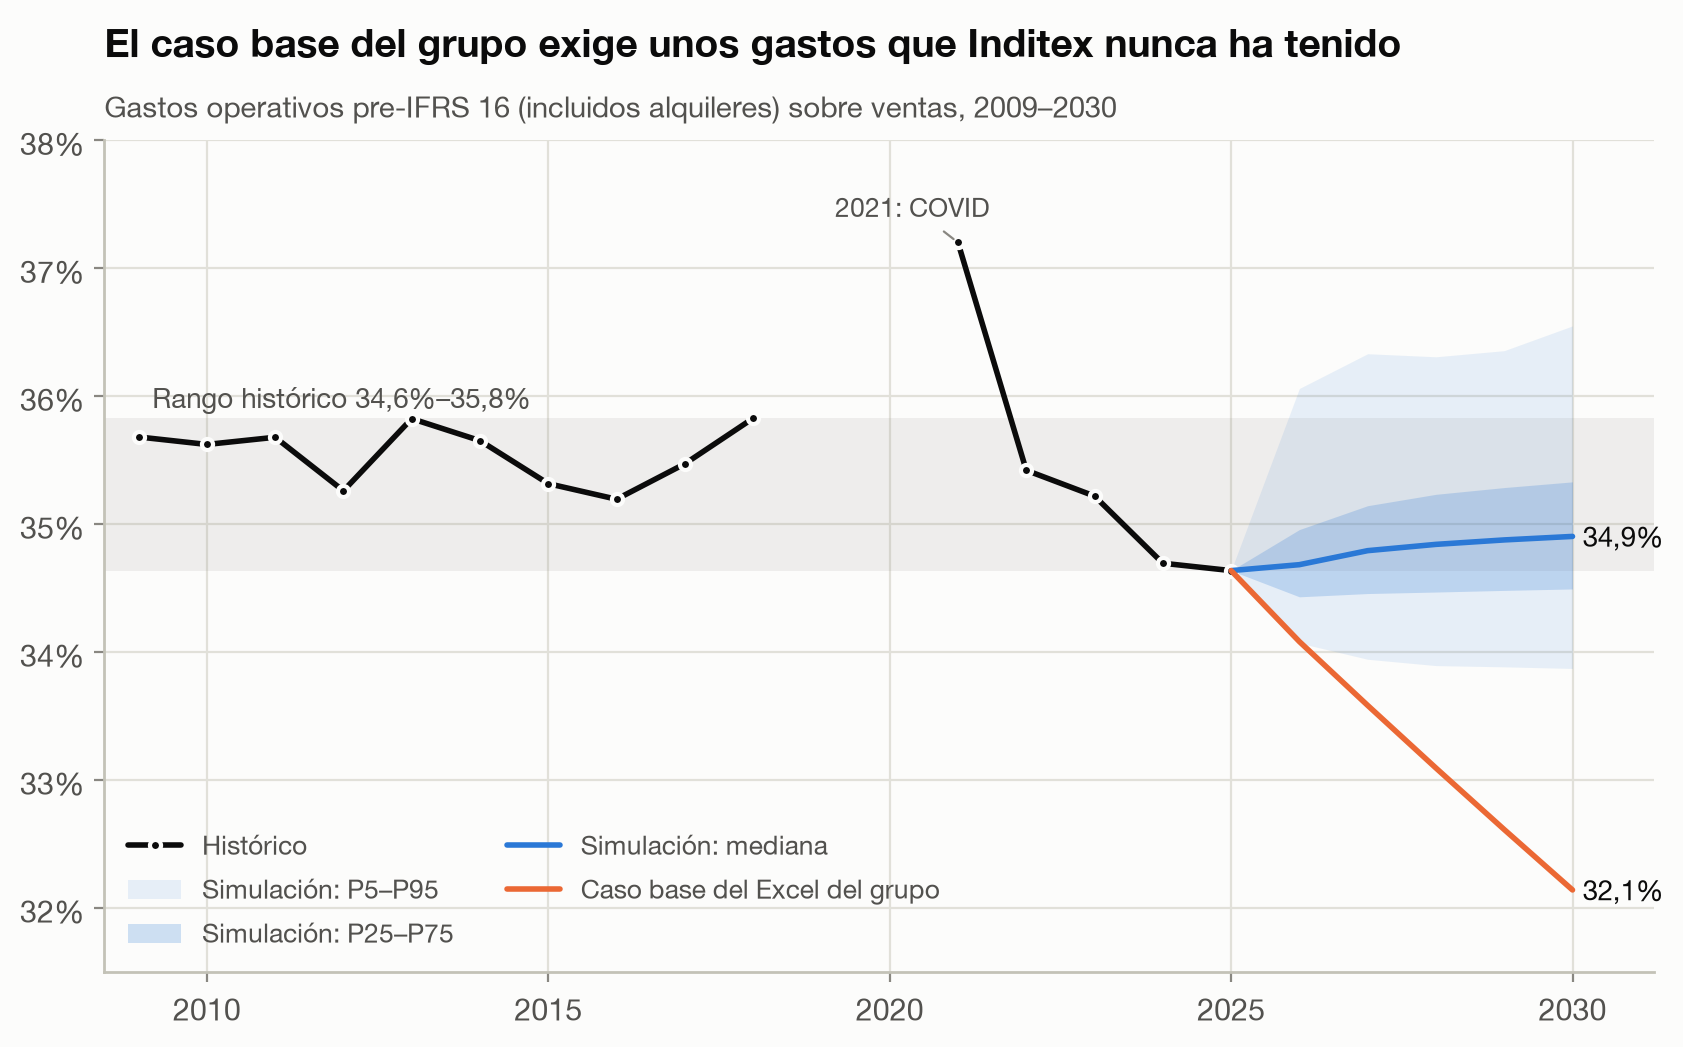

In [7]:
fig("fig1_ratio_gastos.png")

**Esta es la crítica central al Excel del grupo:** su caso base hace crecer los gastos al 4,25 % con ventas al 5,5 %, lo que lleva el ratio al **32,1 % en 2030**, 2,5 puntos por debajo del mínimo de 17 años. El margen EBITDA pre-IFRS 16 pasaría del 23,7 % al 26,1 %, un récord histórico sin una palanca que lo explique.

### 4.2 Resto de procesos

* **Margen bruto:** AR(1) (Ornstein–Uhlenbeck discreto) $m_t = \mu + \phi(m_{t-1}-\mu) + \sigma\varepsilon_t$ estimado en 2009–2025.
* **Crecimiento orgánico:** superficie (1,8 %) + productividad de largo plazo (≈ inflación 2 % + mejora real 2 %). Contraste independiente: la tendencia histórica del crecimiento reportado, extrapolada a 2026–30, da un 3,9 %, frente al 3,7 % de nuestro árbol (orgánico − divisa). **Dos métodos distintos coinciden.**
* **Divisa:** media y volatilidad de los 11 años con ambos crecimientos publicados; para 2026, la guía de Inditex (−1 % a tipos actuales).
* **Crisis tipo COVID:** 1 evento en 25 años cotizando → probabilidad anual ~ Beta(1,5; 24,5) (prior de Jeffreys), media 5,8 %. Caída de ventas −25 % ± 5 % con rebote del 90 % al año siguiente (FY2020 −28 %, FY2021 +36 %). En el año de la crisis las existencias no bajan (stock ya comprado) y los proveedores sí: el circulante negativo **se convierte en salida de caja**.
* **Capex ordinario:** 2026 = **2.300 M€, la guía de Inditex** (≈ 5,5 % de ventas); después, la media 2022–2026e (4,8 %), sin el plan logístico extraordinario de 900 M€/año ya terminado. El Excel usa 5,2 % todos los años.
* **Margen bruto 2026:** la guía de Inditex es «estable ±50 pb», coherente con el AR(1) estimado.
* **Correlaciones** entre shocks, estimadas y encogidas al 50 % hacia cero por el tamaño muestral (*shrinkage*).

In [8]:
o["cal"].table()

,parámetro,valor,incertidumbre (σ),origen,cómo se obtiene
0,fx_mean,-0.020,0.005,estimado,Media de (1+g_reportado)/(1+g_tc_constante)-1 en 11 años con dato
1,fx_sd,0.016,0.000,estimado,Desviación típica anual del efecto divisa
2,org_sd,0.027,0.000,estimado,"σ de los residuos del crecimiento a tc constante sin tendencia (10 años, sin COVID)"
3,org_phi,0.018,0.000,estimado,AR(1) del crecimiento sin tendencia (15 pares de años consecutivos)
4,trend_reported_growth,0.039,0.000,estimado,"Tendencia lineal del crecimiento reportado (pendiente -0.47 pp/año), media 2026-30"
5,space_growth,0.018,0.005,estimado,"Crecimiento neto de superficie 2023-25 (m2 totales, informes anuales)"
6,org_mean,0.058,0.010,criterio,Superficie + productividad por m2 a largo plazo (≈ inflación 2 % + mejora real 2 %); contraste: tendencia reportada ...
7,org_start,0.070,0.000,estimado,"Crecimiento a tc constante FY2025 (7,0 %)"
8,gm_mean,0.580,0.009,estimado,Media de largo plazo del AR(1) del margen bruto (17 años)
9,gm_phi,0.771,0.000,estimado,Persistencia AR(1) del margen bruto


## 5. Simulación de Monte Carlo

Para cada uno de los 20.000 caminos:

1. Se sortean los **parámetros de largo plazo** de ese camino (crecimiento, margen, ratio de gastos, capex, circulante, probabilidad de crisis) desde su distribución de incertidumbre → **incertidumbre paramétrica**.
2. Año a año se generan **shocks correlacionados** (Cholesky) para crecimiento, margen, gastos y divisa, y se sortea si hay crisis → **incertidumbre de proceso**.
3. Se construye la cuenta de resultados, el capex y el circulante, y se pasa por el **motor LBO** (cascada de deuda, cash sweep, PIK, límite fiscal del 30 %).

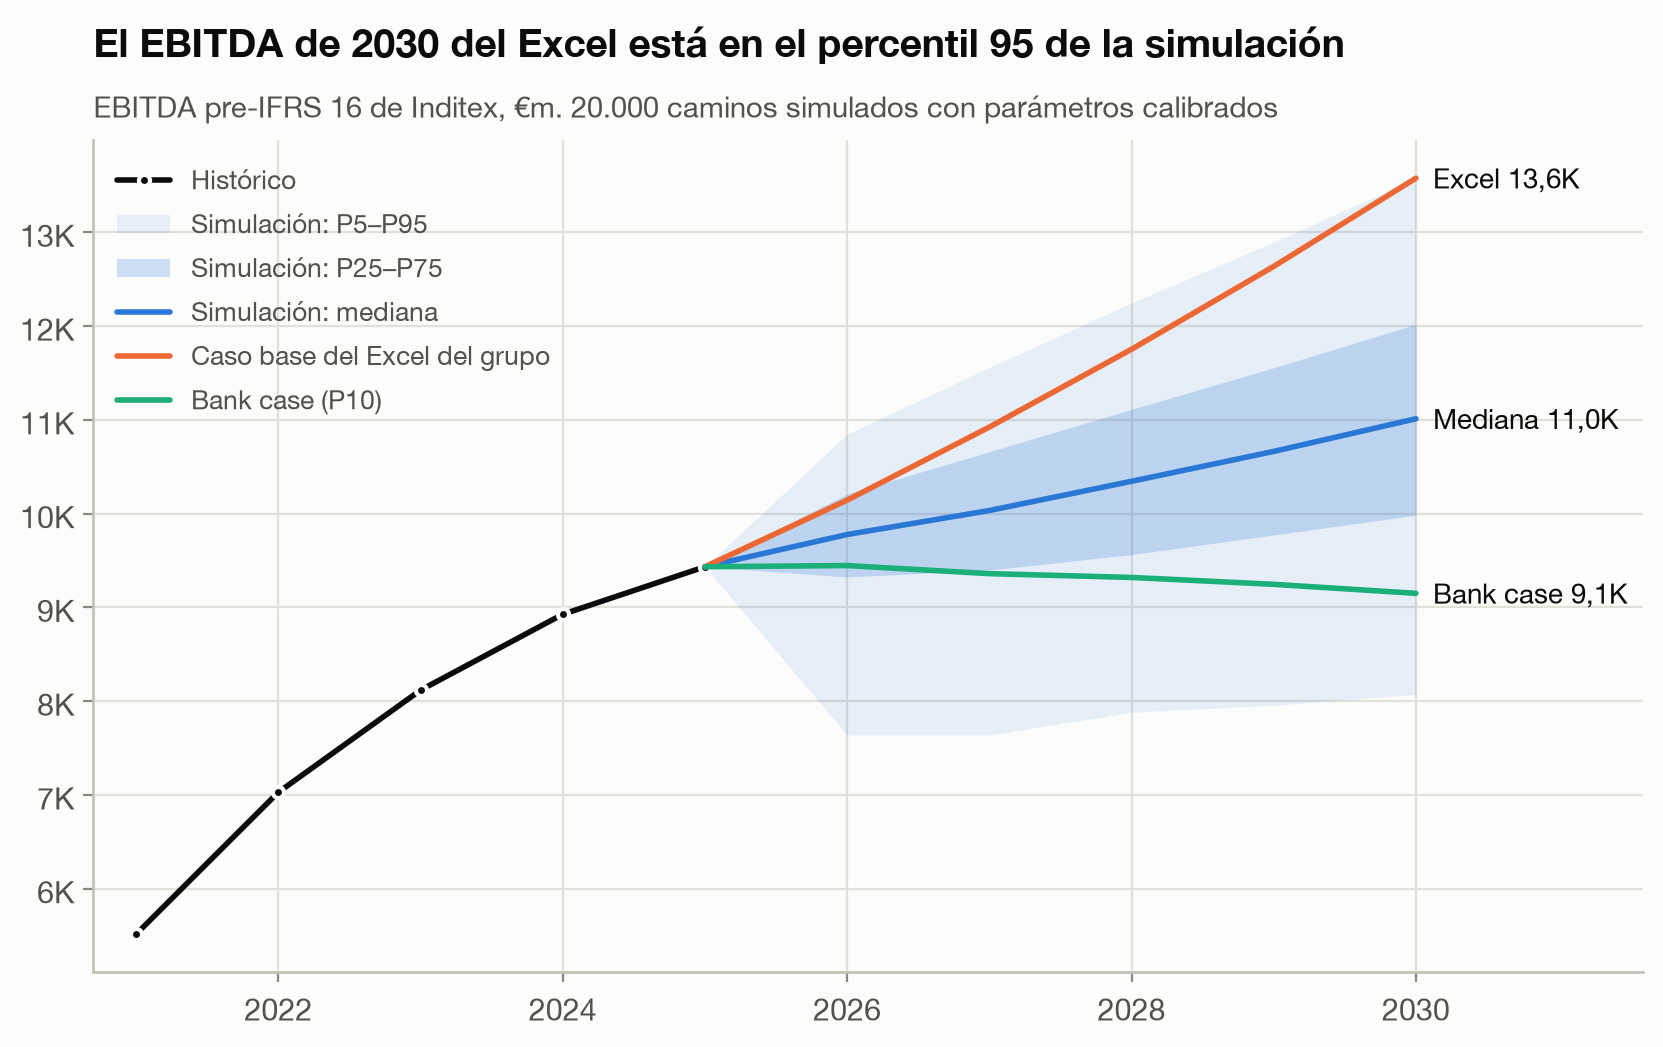

In [9]:
fig("fig3_ebitda_simulado.png")

In [10]:
A.pct(o["op"].ebitda_pre).style.format("{:,.0f}").set_caption("EBITDA pre-IFRS 16 simulado (€m)")

,P5,P25,P50,P75,P95
2026,"7,640","9,324","9,777","10,209","10,847"
2027,"7,638","9,397","10,033","10,660","11,559"
2028,"7,881","9,563","10,344","11,111","12,245"
2029,"7,956","9,772","10,663","11,555","12,894"
2030,"8,073","9,983","11,011","12,019","13,575"


## 6. Los casos para el Excel (Bull, Base, Bear y Bank case)

Cada caso es la **mediana, año a año, de los drivers de los caminos cuyo EBITDA 2030 cae en su percentil** (± 2,5 puntos): Bull = P80, Base = P50, Bear = P20 y **Bank case = P10**, el caso pesimista con el que los bancos fijan los covenants. Así cada caso es una trayectoria coherente y no una mezcla arbitraria de hipótesis.

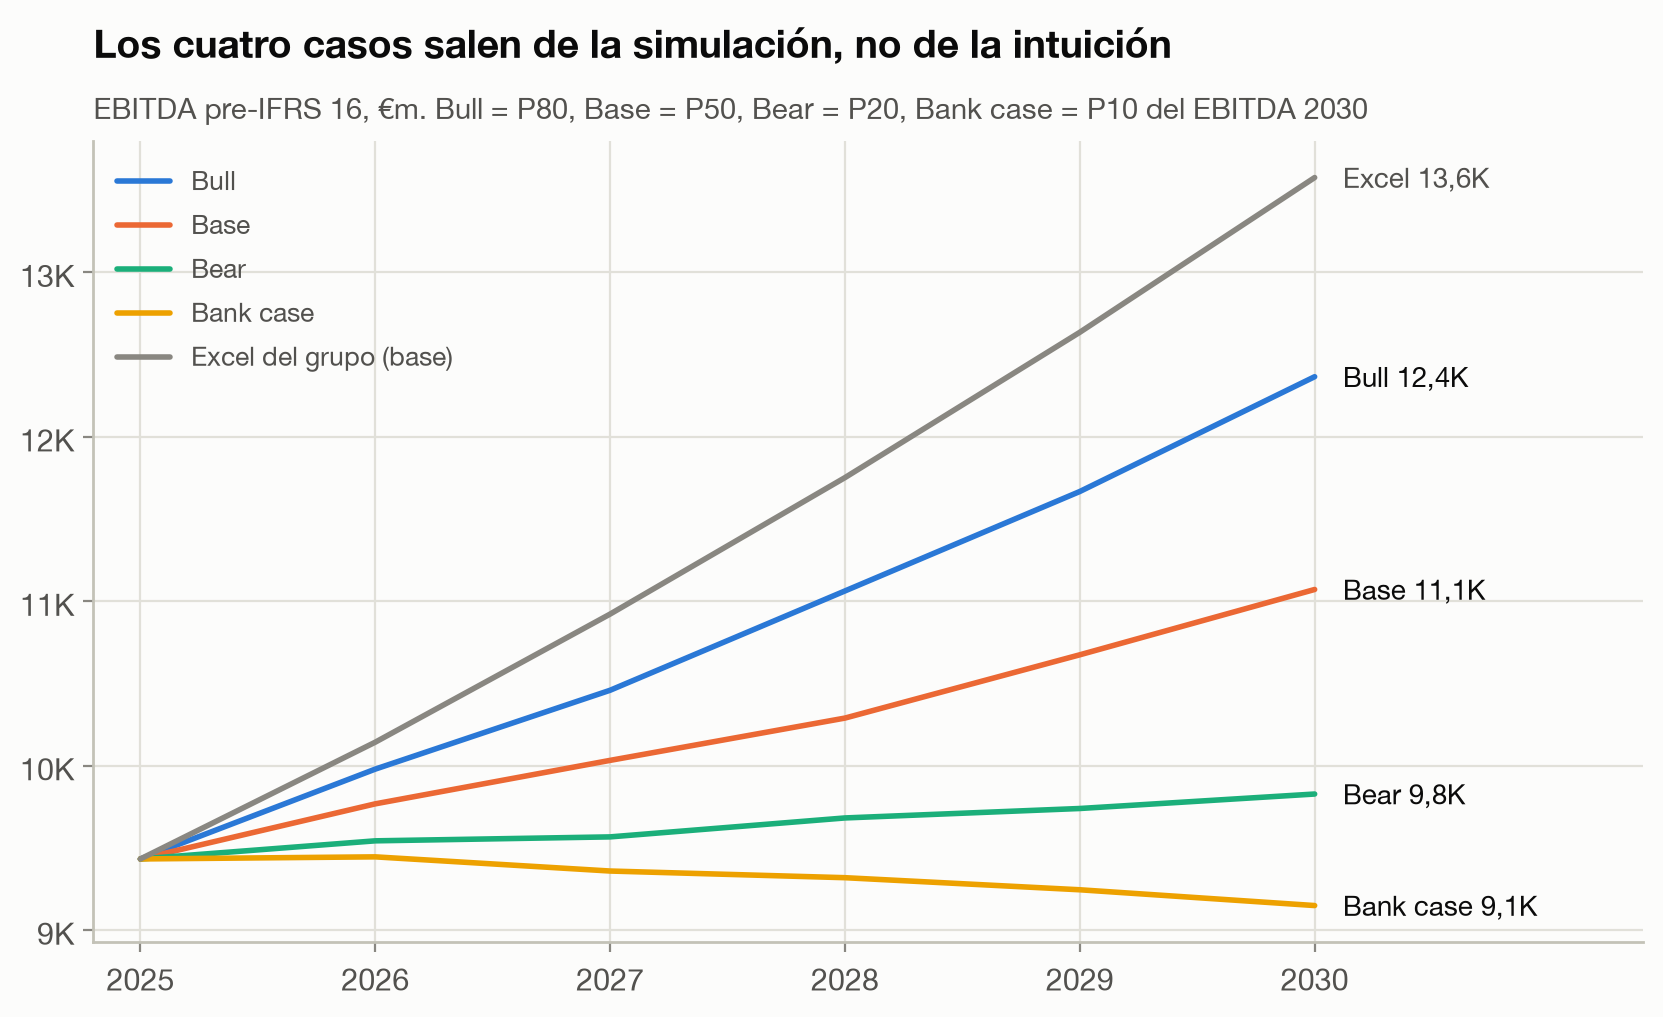

In [11]:
fig("fig9_casos.png")

In [12]:
case_summary(o)

,Bull,Base,Bear,Bank case,Excel del grupo (base)
Percentil (EBITDA 2030),80.000,50.000,20.000,10.000,95.020
Crecimiento ventas TACC 25-30,0.052,0.037,0.022,0.013,0.055
Margen EBITDA pre-IFRS 16 2030,0.240,0.231,0.221,0.215,0.261
EBITDA pre-IFRS 16 2030 (€m),"12,365.787","11,071.829","9,827.905","9,149.603","13,576.948"
CFADS acumulado 26-30 (€m),"39,152.381","36,130.204","33,295.397","31,727.472","41,591.548"
DSCR mínimo,1.348,1.173,1.011,0.913,1.496
Deuda senior neta / EBITDA 2030,0.939,1.344,1.826,2.146,0.660
TIR sponsor,0.085,0.052,0.015,-0.008,0.113
MoM sponsor,1.507,1.287,1.076,0.961,1.710


In [13]:
# Filas 10-17 del Excel (pegar en N10:R17 de la hoja LBO). Caso base:
A.excel_rows(o["case_drivers"]["Base"])

,2026,2027,2028,2029,2030
Revenue growth (% YoY),0.043,0.036,0.033,0.037,0.037
Gross margin (% of revenues),0.582,0.581,0.580,0.580,0.580
OpEx growth (% YoY),0.048,0.040,0.035,0.037,0.037
Fixed lease cash outflow growth (%),0.038,0.038,0.038,0.038,0.038
Capex (% of revenues),0.055,0.048,0.048,0.048,0.048
Inventory (% of revenues),0.084,0.084,0.084,0.084,0.083
Receivables (% of revenues),0.029,0.029,0.029,0.029,0.029
"Payables (% of revenues, negative)",-0.215,-0.216,-0.215,-0.215,-0.215


## 7. Rentabilidad del sponsor

El motor LBO está validado contra el Excel de Javi: con sus hipótesis (prima 5 %, deuda 6x) reproduce el equity de 119.586,7 M€, el cheque del sponsor de 65.818,6 M€, la TIR del 11,95 % y cada DSCR, saldo de deuda e impuesto año a año.

In [14]:
j = run(excel_base_operating(), JAVI_DEAL)
pd.Series({"Equity total (E196)": j["su"]["equity"], "Cheque del sponsor (E208)": j["su"]["sponsor"],
           "TIR (F229)": j["irr"][0], "MoM (F230)": j["mom"][0], "DSCR 2026 (N136)": j["dscr"][0,0]}).to_frame("motor Python")

,motor Python
Equity total (E196),"119,586.725"
Cheque del sponsor (E208),"65,818.601"
TIR (F229),0.120
MoM (F230),1.759
DSCR 2026 (N136),2.889


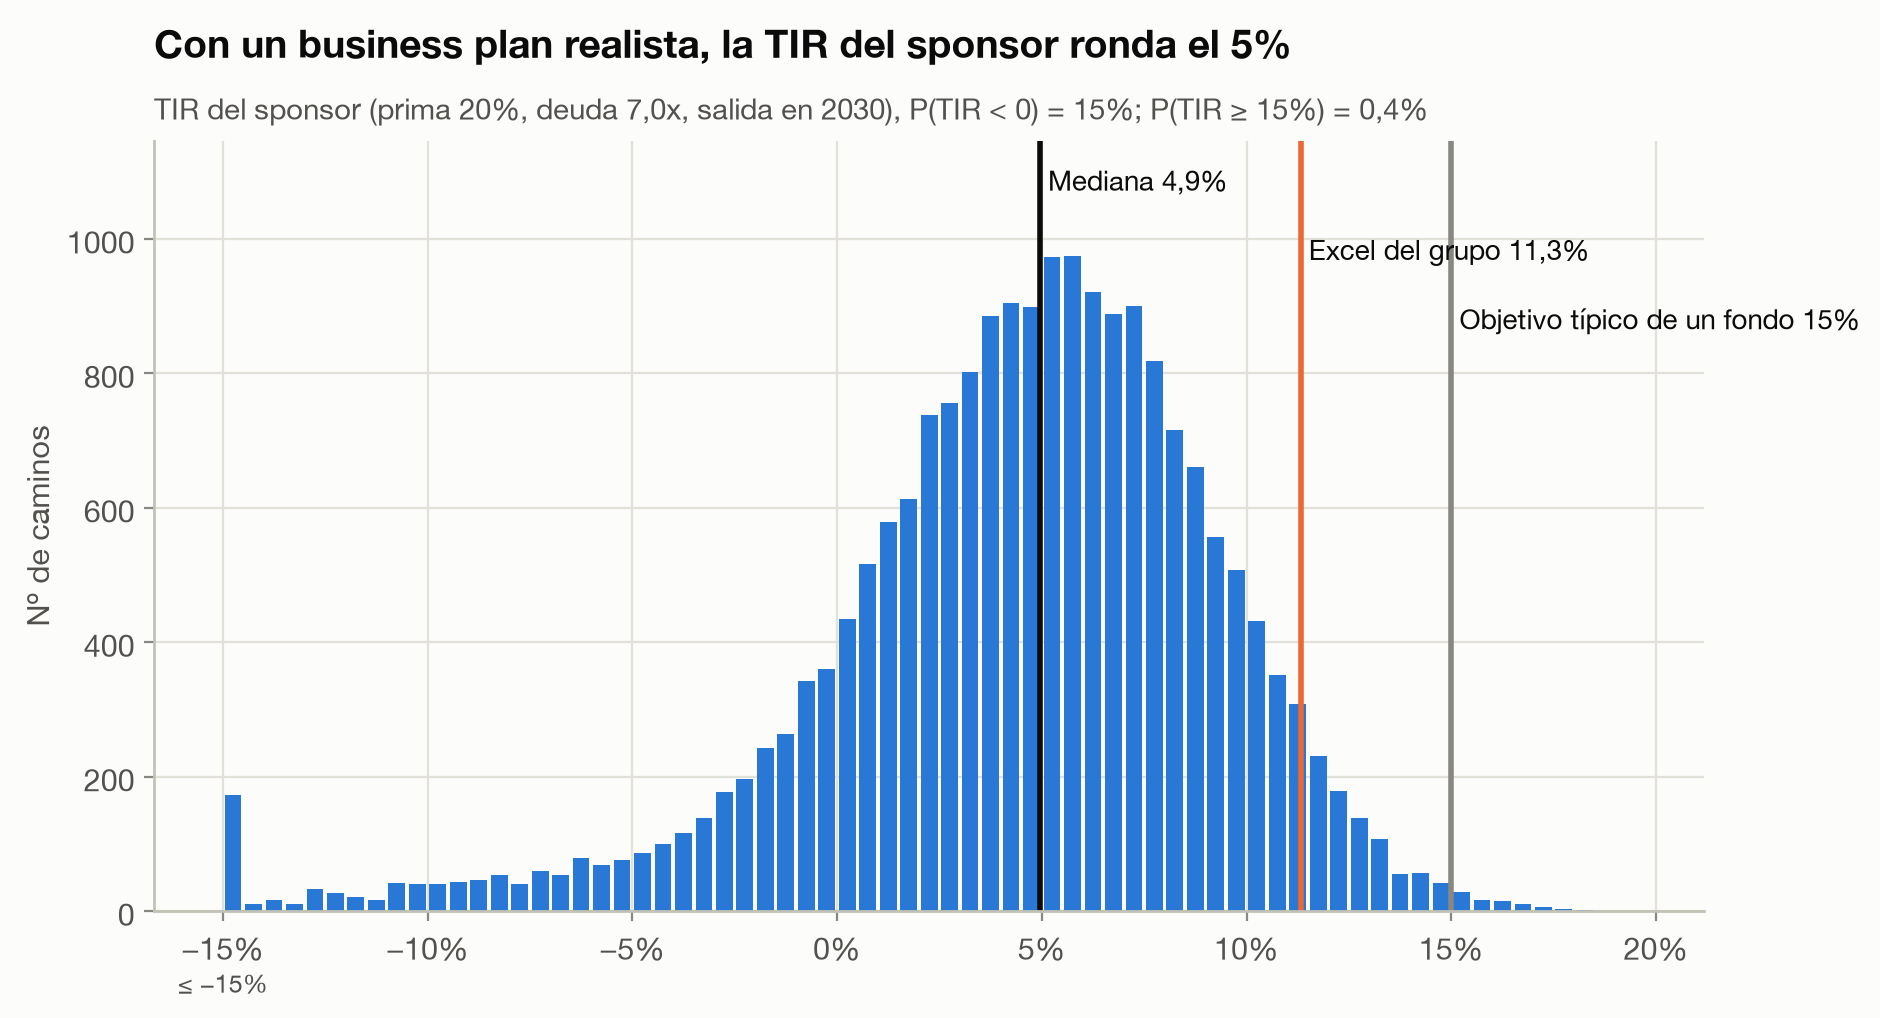

In [15]:
fig("fig4_distribucion_tir.png")

In [16]:
pd.DataFrame({"Business plan simulado": A.risk_summary(o["res"])})

,Business plan simulado
TIR mediana,0.049
TIR P10,-0.015
TIR P90,0.100
MoM mediano,1.273
P(TIR < 0),0.149
P(TIR ≥ 15 %),0.004
P(TIR ≥ 20 %),0.000
"P(DSCR mínimo < 1,2x)",0.707
"P(DSCR mínimo < 1,0x)",0.382
P(caja < 0 con la RCF agotada),0.003


## 8. ¿Hasta dónde se puede apalancar?

### 8.1 Más deuda no sube la TIR (Modigliani–Miller en acción)

La rentabilidad del equity apalancado es aproximadamente:

$$\text{TIR}_{\text{equity}} \approx r_A + \big(r_A - r_D(1-t)\big)\,\frac{D}{E}$$

La deuda solo sube la TIR si el activo rinde más que lo que cuesta la deuda después de impuestos. Comprando Inditex a **20,8x EBITDA**, el activo rinde ≈ 5 % (TIR con deuda 0x). La senior cuesta 5,85–6,85 % × (1 − 22,4 %) ≈ 4,5–5,3 %: **apalancamiento casi neutro** (+0,3 pp de TIR hasta 4,5x). El PIK (10,5 %) y el vendor loan (10 %) cuestan más que el activo: **apalancamiento negativo**, cada vuelta adicional **resta** TIR.

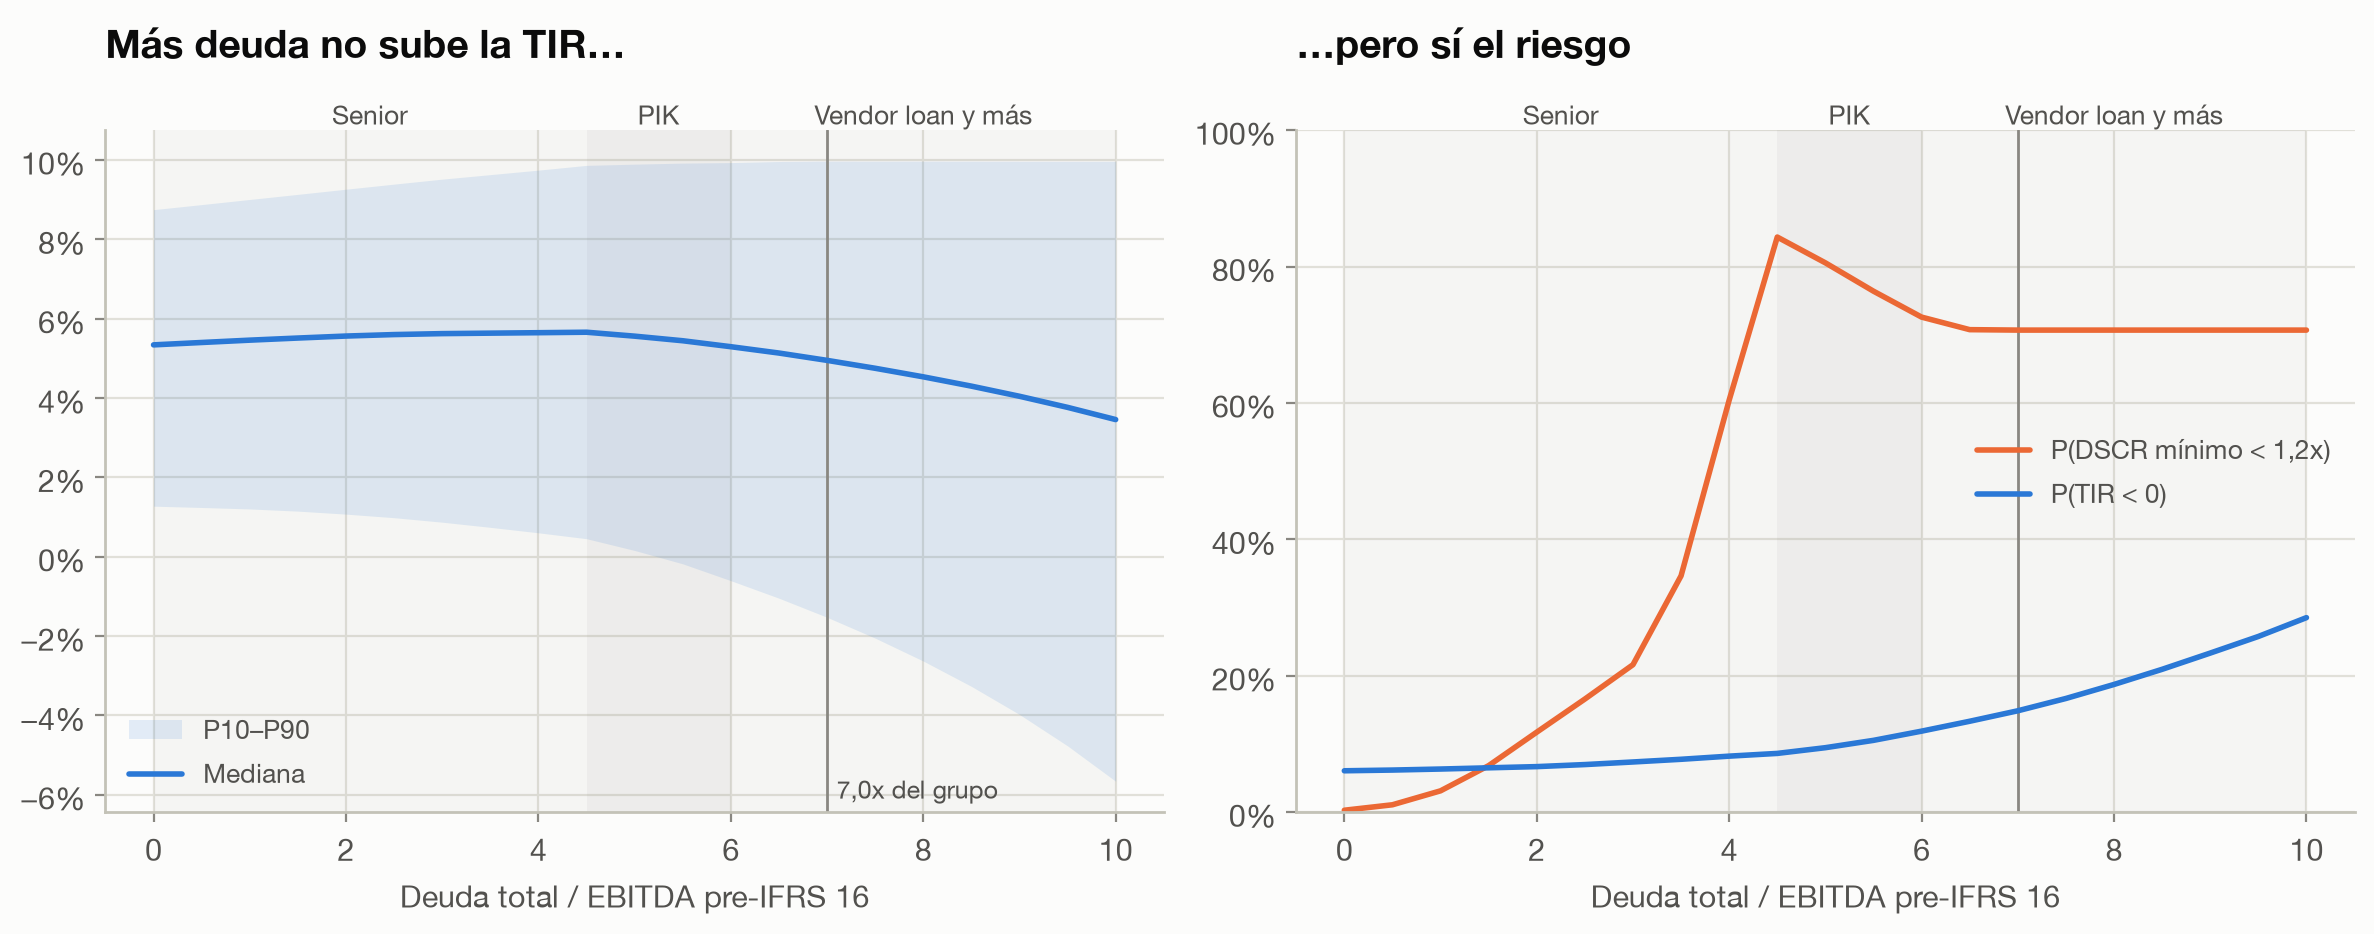

In [17]:
fig("fig5_frontera_apalancamiento.png")

In [18]:
o["frontier"][["TIR mediana", "TIR P10", "P(TIR < 0)", "P(DSCR mínimo < 1,2x)", "P(caja < 0 con la RCF agotada)"]].iloc[::2]

,TIR mediana,TIR P10,P(TIR < 0),"P(DSCR mínimo < 1,2x)",P(caja < 0 con la RCF agotada)
deuda_x_ebitda,,,,,
0.000,0.053,0.013,0.061,0.003,0.000
1.000,0.055,0.012,0.063,0.031,0.000
2.000,0.056,0.011,0.067,0.117,0.000
3.000,0.056,0.009,0.074,0.216,0.000
4.000,0.056,0.006,0.082,0.604,0.001
5.000,0.056,0.002,0.095,0.805,0.004
6.000,0.053,-0.006,0.119,0.726,0.003
7.000,0.049,-0.015,0.149,0.707,0.003
8.000,0.045,-0.026,0.187,0.707,0.003


*Nota:* entre 4,5x y 6x la probabilidad de incumplir el DSCR **baja** porque el PIK no paga intereses en caja pero sí se deduce fiscalmente (hasta el 30 % del EBITDA): menos impuestos → más CFADS. La probabilidad de quedarse sin caja es casi nula (≈ 0,2 %) gracias a la RCF de 4.000 M€ y a que el PIK no consume caja: **para Inditex el límite de la deuda no es la quiebra sino los covenants y el tamaño del mercado**.

### 8.2 La palanca que sí funciona: la estructura de la senior

El DSCR toca mínimo en 2030 en la mayoría de caminos porque la TLA devuelve el 25 % ese año. Pasando senior de TLA (amortizable) a TLB (bullet con cash sweep), la capacidad de deuda con el mismo riesgo sube mucho, **sin cambiar la TIR**. Optimización con restricción probabilística: máxima deuda senior tal que P(DSCR mínimo < 1,2x) ≤ 5 %.

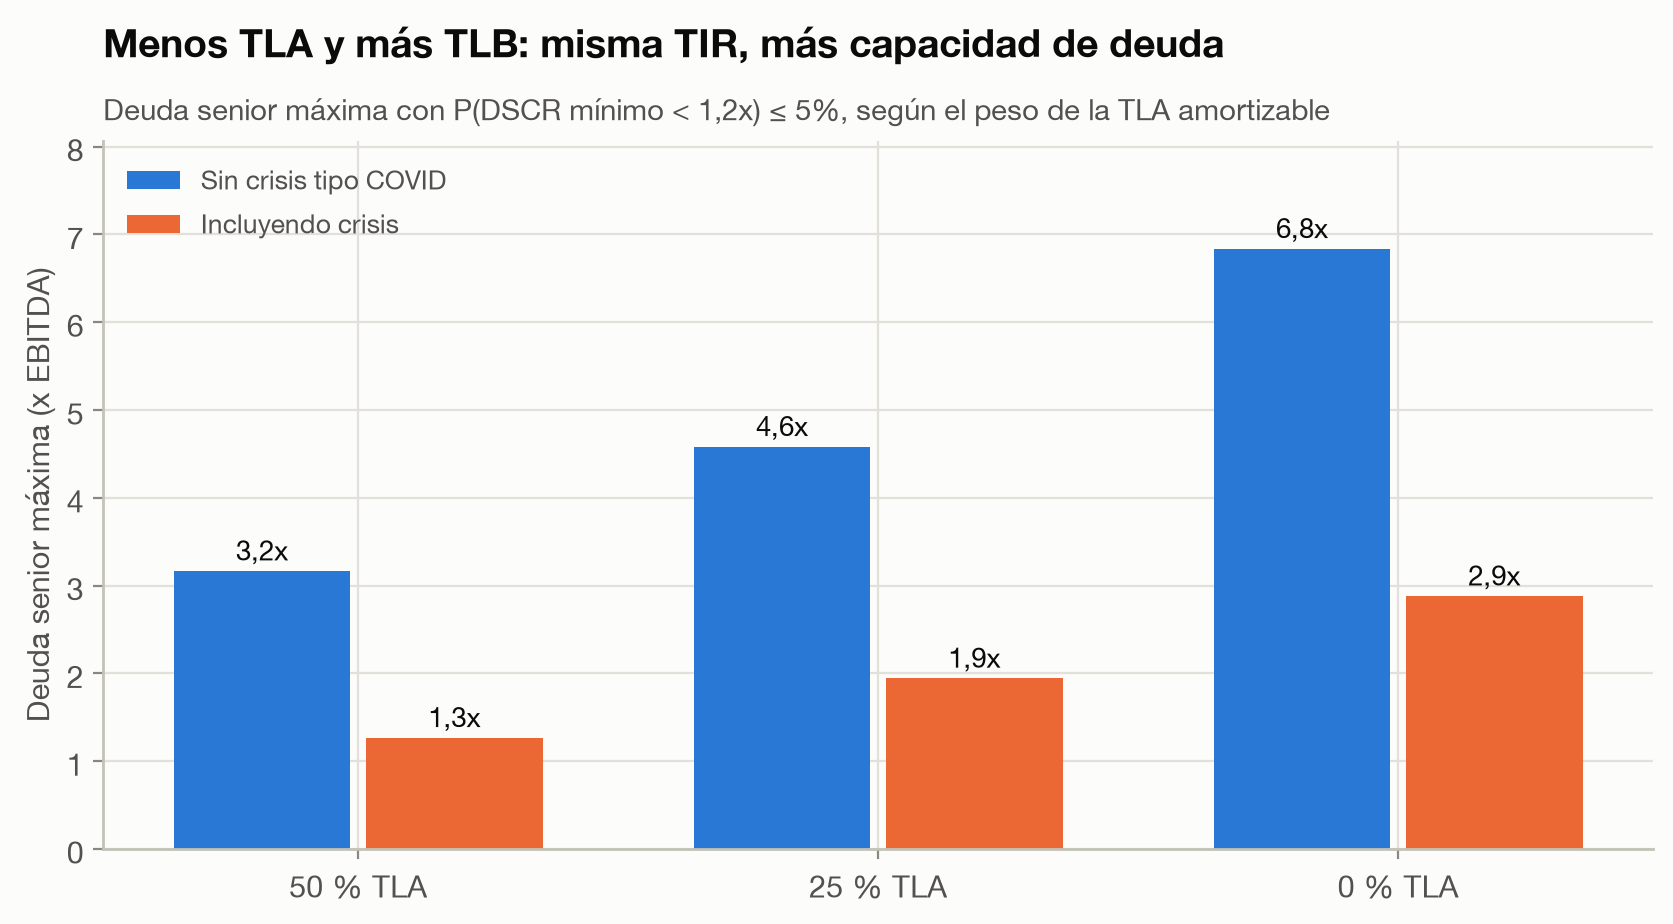

In [19]:
fig("fig6_capacidad_senior.png")

In [20]:
o["capacity"].style.format("{:.2f}x")

,Sin crisis tipo COVID,Incluyendo crisis
50 % TLA,3.17x,1.27x
25 % TLA,4.58x,1.94x
0 % TLA,6.84x,2.88x


Con crisis tipo COVID la capacidad cae mucho: en 2020 la práctica de mercado fue conceder *covenant holidays*. **Recomendación para el compañero de deuda:** senior ≈ 4,5x con un 25 % de TLA (en vez del 50 %) y el resto en TLB/bonos con cash sweep; *equity cure* y *covenant holiday* negociados para un evento de crisis.

## 9. ¿Qué explica el riesgo de la TIR?

Con factores correlacionados (p. ej. crecimiento y gastos, por el apalancamiento operativo) los índices de Sobol de primer orden suman más de 1 y no se pueden leer como un reparto. Usamos los **valores de Shapley sobre el R²** (método LMG): para cada driver se promedia su aportación marginal al R² sobre todos los subconjuntos de los demás, y el reparto suma exactamente el R² total. Aquí el múltiplo de salida también es aleatorio (triangular entre 15x, el de mercado 17,1x y el de entrada 20,8x).

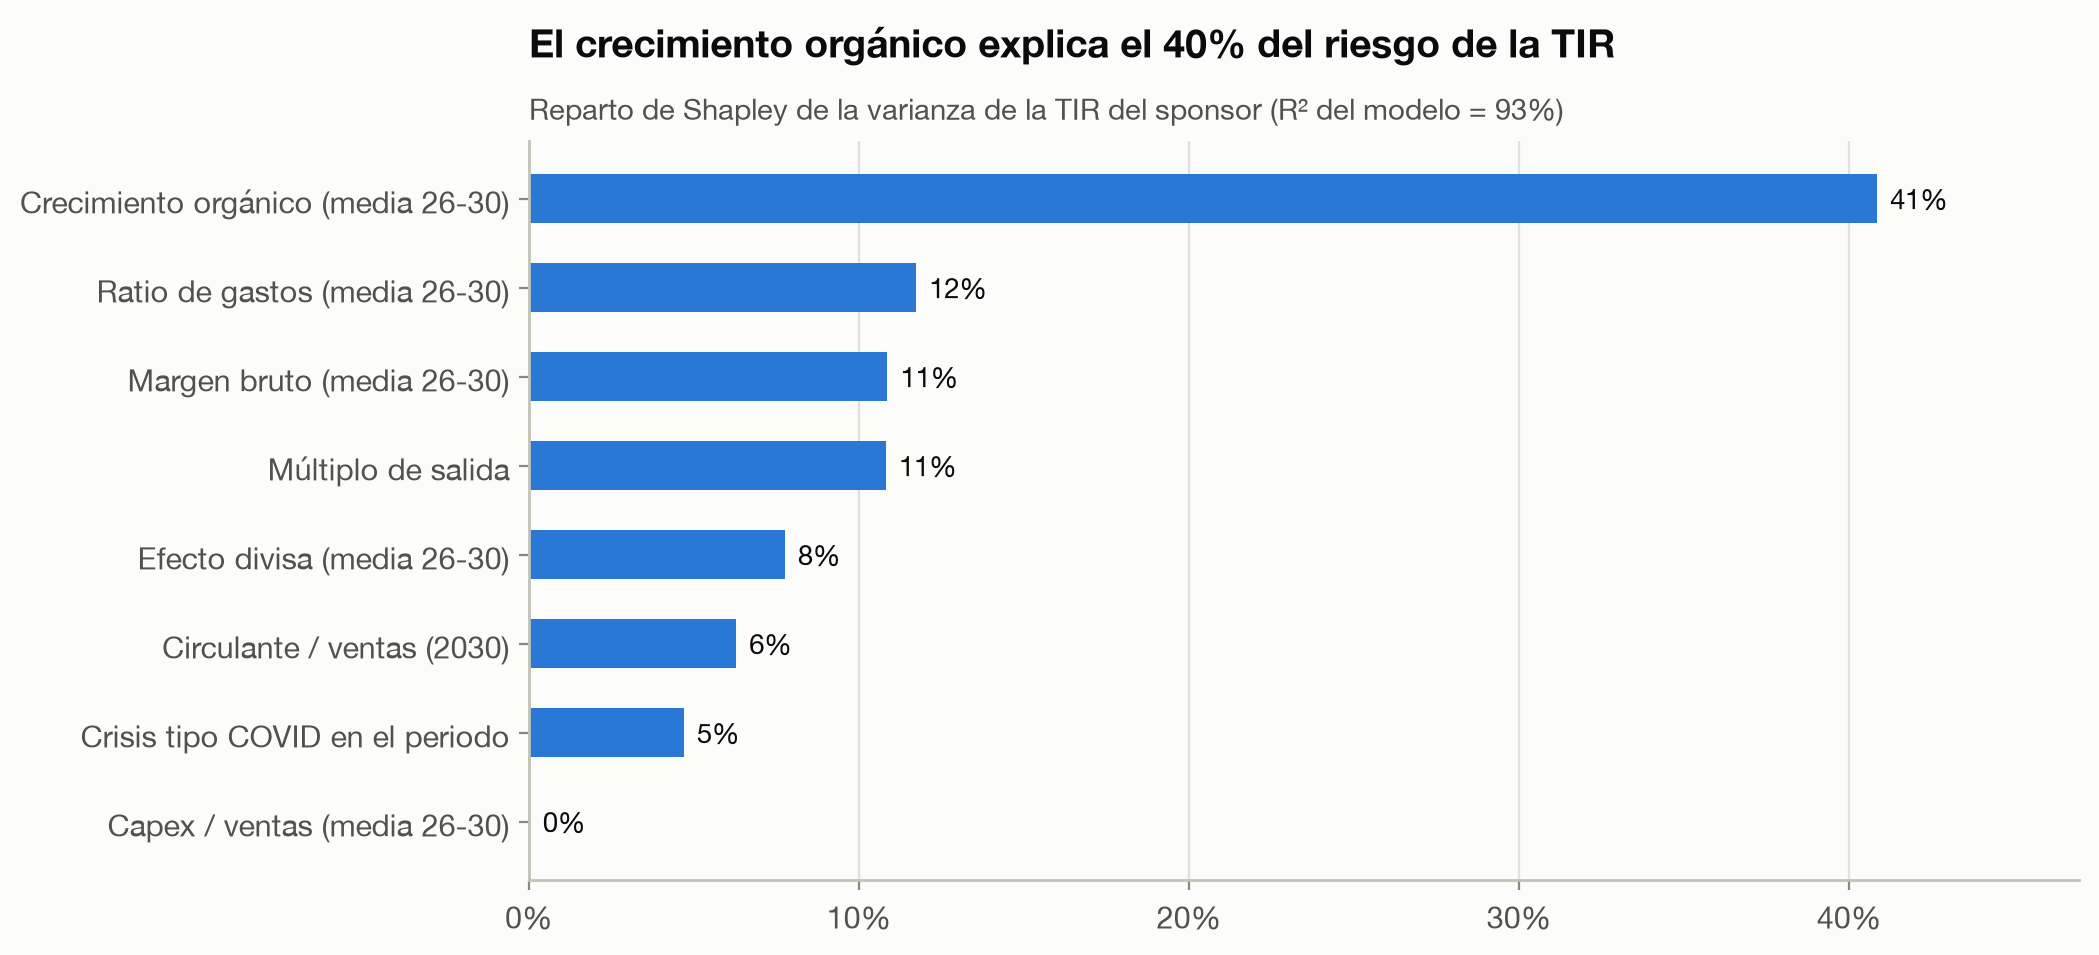

In [21]:
fig("fig7_shapley_tir.png")

**Lectura:** el crecimiento orgánico explica el 40 % del riesgo: es el driver donde la due diligence comercial (aperturas, online, precios) aporta más valor. El capex apenas importa.

## 10. ¿Qué hay que creerse para que el LBO funcione?

Ingeniería inversa: EBITDA 2030 necesario para una TIR del 15 % / 20 % y su probabilidad según la simulación.

In [22]:
o["required"].style.format({"TIR objetivo": "{:.0%}", "Múltiplo de salida": "{:.1f}x", "EBITDA 2030 necesario": "{:,.0f}",
                            "TACC EBITDA 2025-30 necesaria": "{:.1%}", "Probabilidad según la simulación": "{:.2%}"})

,TIR objetivo,Múltiplo de salida,EBITDA 2030 necesario,TACC EBITDA 2025-30 necesaria,Probabilidad según la simulación
0,15%,17.1x,"19,271",15.4%,0.00%
1,15%,20.8x,"15,880",11.0%,0.18%
2,20%,17.1x,"23,095",19.6%,0.00%
3,20%,20.8x,"19,031",15.1%,0.00%


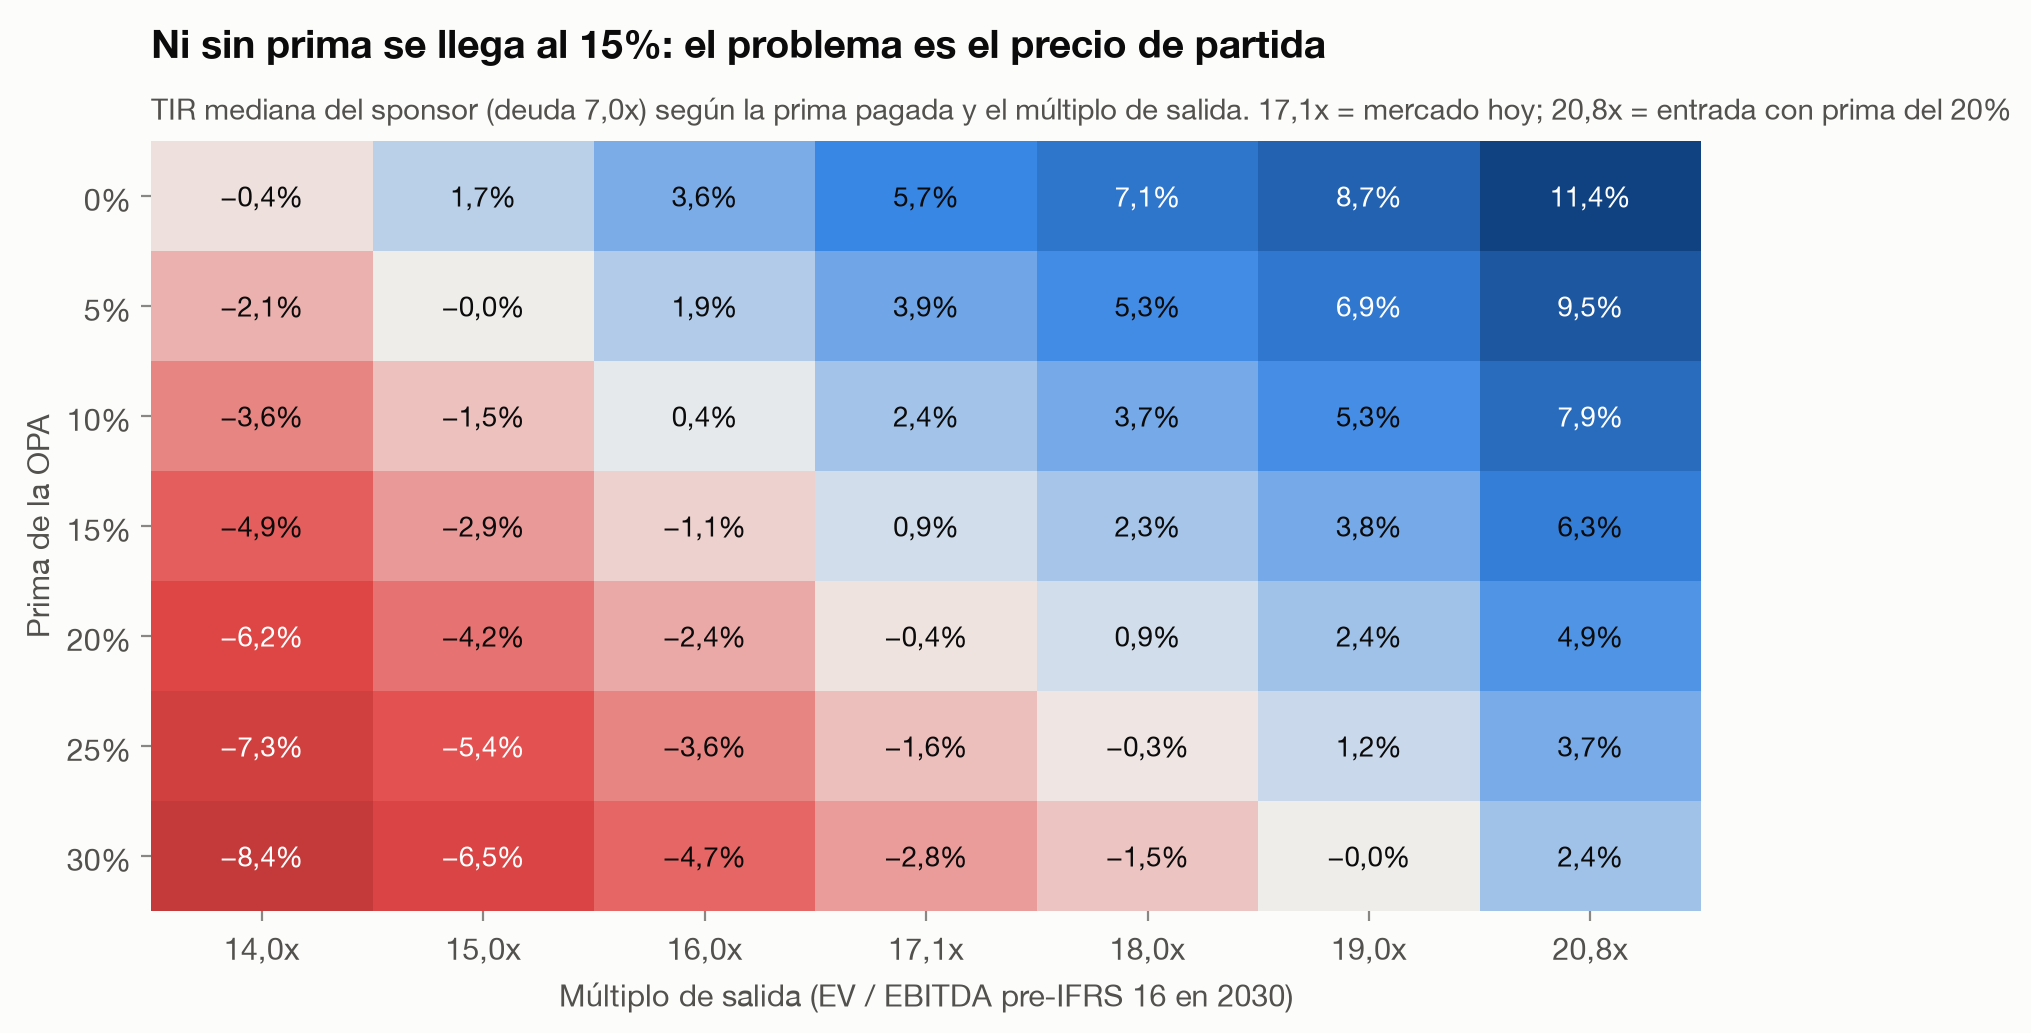

In [23]:
fig("fig8_prima_vs_salida.png")

**Conclusión de valoración:** ni comprando sin prima se alcanza el 15 % salvo vendiendo muy caro. Inditex cotiza a ≈ 17x EBITDA pre-IFRS 16 porque el mercado ya descuenta su calidad. **El LBO solo funciona si el sponsor aporta algo que el mercado no está pagando**: crecimiento por encima del histórico, mejora estructural de márgenes o un precio de entrada sin prima de control (por ejemplo, entrando junto a la familia).

## 11. Plan de creación de valor (caso aparte)

Palancas típicas de un sponsor, escalonadas en 4 años: capex −0,3 pp de ventas, gastos −0,4 pp, proveedores +1 pp y existencias −0,3 pp de ventas. Se presentan aparte porque los bancos dimensionan sobre el EBITDA actual, no sobre el que tendría la empresa con sinergias.

In [24]:
pd.DataFrame({"Sin plan": A.risk_summary(o["res"]), "Con plan de creación de valor": A.risk_summary(o["vcp_res"])})

,Sin plan,Con plan de creación de valor
TIR mediana,0.049,0.056
TIR P10,-0.015,-0.007
TIR P90,0.100,0.106
MoM mediano,1.273,1.315
P(TIR < 0),0.149,0.122
P(TIR ≥ 15 %),0.004,0.007
P(TIR ≥ 20 %),0.000,0.000
"P(DSCR mínimo < 1,2x)",0.707,0.593
"P(DSCR mínimo < 1,0x)",0.382,0.310
P(caja < 0 con la RCF agotada),0.003,0.002


## 12. Limitaciones (para defenderlas antes de que pregunten)

* **Datos 2005–2020** de resultados publicados y prensa financiera, contrastados entre fuentes; el EBITDA 2018 (IAS 17) no está verificado. 2021–2025 sale de las cuentas anuales.
* **Muestras cortas** (11–17 años por proceso): por eso se incorpora la incertidumbre sobre los propios parámetros y se encogen las correlaciones.
* **Efecto divisa:** se proyecta su media histórica (−2,0 pp). Si el euro se debilitara, el crecimiento reportado sería mayor.
* **Múltiplo de salida:** por coherencia con el Excel, el caso central sale al múltiplo de entrada (20,8x), una hipótesis generosa. El mapa de calor muestra la sensibilidad.
* **Covenants en crisis:** el modelo no simula renegociaciones; se reporta la probabilidad con y sin crisis.
* Perímetro: se supone aceptación ≥ 90 % y squeeze-out, de modo que el 100 % del CFADS sube a la BidCo como dividendo.

## 13. Exportación

* `output/Business_Plan_Inditex.xlsx`: casos (en formato de las filas del Excel), PyG y caja por caso, percentiles de la simulación, apalancamiento, calibración e histórico.
* `Excels/Inditex_LBO_Rollover50_BusinessPlan.xlsx`: copia del modelo de Javi con este business plan conectado año a año (selector 1–4 en F9; F18 = 0 vuelve a los presets planos). Verificado: reproduce los resultados del motor Python al sexto decimal.

In [25]:
from bp.export import business_plan_workbook, integrated_group_model
print(business_plan_workbook(o, ROOT / "output" / "Business_Plan_Inditex.xlsx").relative_to(ROOT.parent))
src = ROOT.parent / "Excels" / "Inditex_LBO_Rollover50.xlsx"   # modelo de Javi (rama Javi)
if src.exists():
    print(integrated_group_model(o, src, ROOT.parent / "Excels" / "Inditex_LBO_Rollover50_BusinessPlan.xlsx").relative_to(ROOT.parent))
else:
    print("Modelo de Javi no encontrado en Excels/: el Excel integrado no se regenera (el existente sigue siendo válido).")

Business Plan/output/Business_Plan_Inditex.xlsx
Modelo de Javi no encontrado en Excels/: el Excel integrado no se regenera (el existente sigue siendo válido).
